In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Определяем рабочую директорию
HERE = Path.cwd()

# Датасеты находятся в соседней папке datasets/csv
DATA_DIR = HERE / "datasets" / "csv"

if not DATA_DIR.is_dir():
    DATA_DIR = HERE.parent / "datasets" / "csv"



In [4]:
def correlation_analysis(df, name):

    # Исключаем категориальный признак CLASS
    if name == "Barotrop.csv":
        df = df.drop(columns=["CLASS"])

    # Выбираем только количественные признаки
    numeric_df = df.select_dtypes(include="number")

    # Удаляем признаки с постоянными значениями
    numeric_df = numeric_df.loc[:, numeric_df.nunique() > 1]

    if numeric_df.shape[1] < 2:
        print(f"{name}: недостаточно числовых признаков")
        return None

    # Вычисляем парные коэффициенты корреляции Пирсона
    corr_matrix = numeric_df.corr(method="pearson")

    print(f"\nДатасет: {name}")
    print("Размер:", df.shape)

    display(corr_matrix.round(3))

    # Строим тепловую карту
    plt.figure(figsize=(9, 7))

    sns.heatmap(
        corr_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0
    )

    plt.title(f"Тепловая карта корреляций — {name}")
    plt.tight_layout()
    plt.show()

    # Находим уникальные пары признаков
    pairs = []

    columns = corr_matrix.columns

    for i in range(len(columns)):
        for j in range(i + 1, len(columns)):

            r = corr_matrix.iloc[i, j]

            if pd.notna(r):
                pairs.append({
                    "Признак X": columns[i],
                    "Признак Y": columns[j],
                    "Корреляция r": r,
                    "|r|": abs(r)
                })

    pairs_df = pd.DataFrame(pairs)

    pairs_df = pairs_df.sort_values(
        by="|r|",
        ascending=False
    )

    print("Пары признаков по силе корреляции:")
    display(pairs_df.round(3))

    return corr_matrix, pairs_df


Датасет: Barotrop.csv
Размер исходной выборки: (37, 3)


,LONGITUD,LATITUDE,CLASS
0,59.0,17.0,100.0
1,59.5,21.0,100.0
2,60.0,12.0,100.0
3,60.5,16.0,100.0
4,61.0,13.0,100.0



Датасет: Barotrop.csv
Размер: (37, 2)


,LONGITUD,LATITUDE
LONGITUD,1.000,0.081
LATITUDE,0.081,1.000


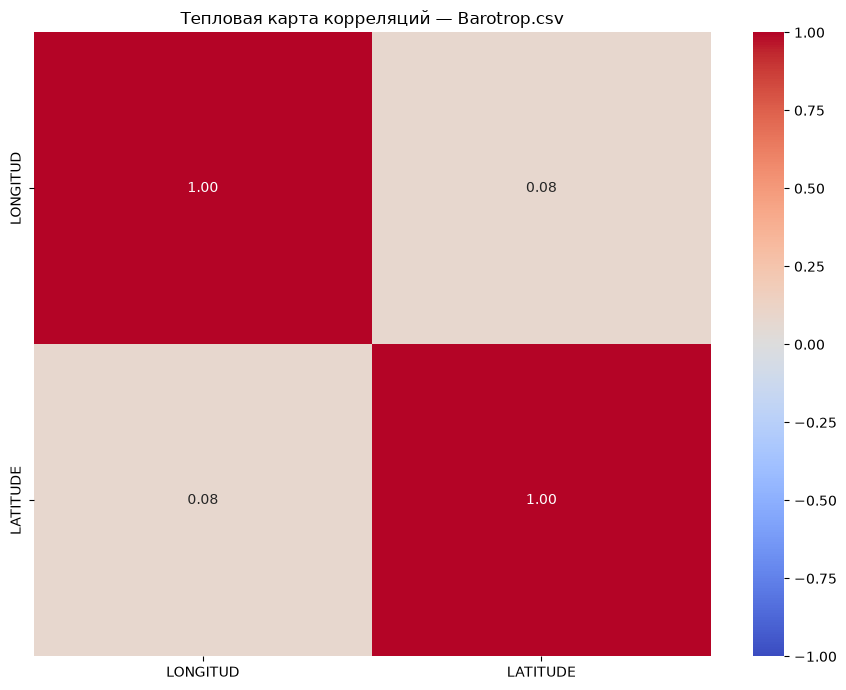

Пары признаков по силе корреляции:


,Признак X,Признак Y,Корреляция r,|r|
0,LONGITUD,LATITUDE,0.081,0.081



Датасет: Chemical_process.csv
Размер исходной выборки: (100, 5)


,YIELD,HCL,NH3,H20,CATALYST
0,59.566840,12.071825,12.420652,12.226249,9.342860
1,61.221973,9.930952,10.858867,10.124134,8.180258
2,61.031099,9.775307,7.836772,7.776803,8.289666
3,61.848694,9.446776,12.420000,10.551851,11.268426
4,59.427282,11.908399,12.390000,8.208335,10.397275



Датасет: Chemical_process.csv
Размер: (100, 5)


,YIELD,HCL,NH3,H20,CATALYST
YIELD,1.000,-0.504,-0.059,-0.032,-0.012
HCL,-0.504,1.000,0.069,0.161,0.076
NH3,-0.059,0.069,1.000,0.103,0.131
H20,-0.032,0.161,0.103,1.000,-0.092
CATALYST,-0.012,0.076,0.131,-0.092,1.000


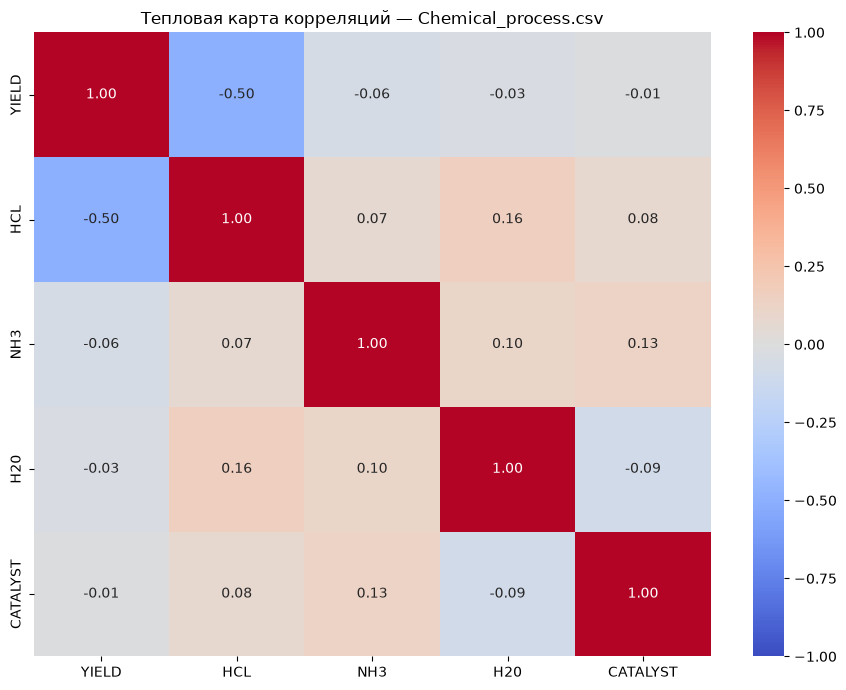

Пары признаков по силе корреляции:


,Признак X,Признак Y,Корреляция r,|r|
0,YIELD,HCL,-0.504,0.504
5,HCL,H20,0.161,0.161
8,NH3,CATALYST,0.131,0.131
7,NH3,H20,0.103,0.103
9,H20,CATALYST,-0.092,0.092
6,HCL,CATALYST,0.076,0.076
4,HCL,NH3,0.069,0.069
1,YIELD,NH3,-0.059,0.059
2,YIELD,H20,-0.032,0.032
3,YIELD,CATALYST,-0.012,0.012



Датасет: Factor.csv
Размер исходной выборки: (100, 10)


,WORK_1,WORK_2,WORK_3,HOBBY_1,HOBBY_2,HOME_1,HOME_2,HOME_3,MISCEL_1,MISCEL_2
0,105.125882,101.658698,115.060337,100.998142,95.184438,100.281271,101.666897,85.553007,104.034599,110.278061
1,77.049018,72.933421,77.485094,72.743695,61.563003,93.854052,95.391729,88.609307,70.115287,72.000301
2,86.016702,82.206478,78.888889,77.951179,91.705126,86.773383,108.070028,93.347801,86.021108,70.687902
3,91.424705,106.106544,95.639818,90.900566,111.466157,100.248399,86.080498,93.822050,101.223914,82.665473
4,113.714315,92.028721,99.078944,79.277424,98.416101,104.012655,83.271087,69.621482,82.820227,70.022295



Датасет: Factor.csv
Размер: (100, 10)


,WORK_1,WORK_2,WORK_3,HOBBY_1,HOBBY_2,HOME_1,HOME_2,HOME_3,MISCEL_1,MISCEL_2
WORK_1,1.000,0.647,0.653,0.598,0.521,0.143,0.145,0.138,0.611,0.549
WORK_2,0.647,1.000,0.732,0.689,0.698,0.143,0.182,0.236,0.709,0.685
WORK_3,0.653,0.732,1.000,0.637,0.630,0.164,0.238,0.255,0.698,0.671
HOBBY_1,0.598,0.689,0.637,1.000,0.805,0.536,0.634,0.583,0.904,0.843
HOBBY_2,0.521,0.698,0.630,0.805,1.000,0.506,0.496,0.482,0.811,0.756
HOME_1,0.143,0.143,0.164,0.536,0.506,1.000,0.658,0.590,0.498,0.425
HOME_2,0.145,0.182,0.238,0.634,0.496,0.658,1.000,0.731,0.644,0.593
HOME_3,0.138,0.236,0.255,0.583,0.482,0.590,0.731,1.000,0.586,0.518
MISCEL_1,0.611,0.709,0.698,0.904,0.811,0.498,0.644,0.586,1.000,0.841
MISCEL_2,0.549,0.685,0.671,0.843,0.756,0.425,0.593,0.518,0.841,1.000


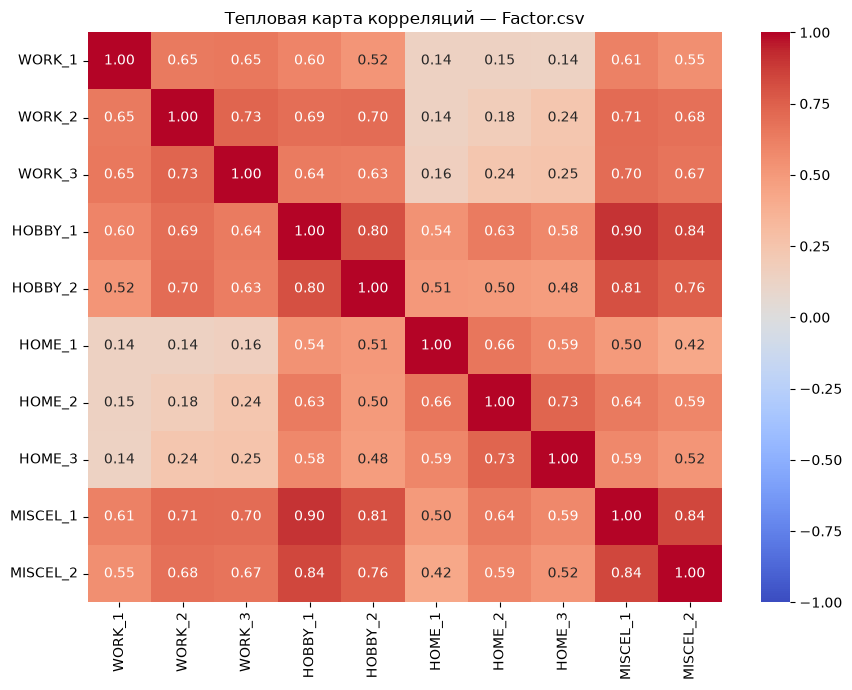

Пары признаков по силе корреляции:


,Признак X,Признак Y,Корреляция r,|r|
28,HOBBY_1,MISCEL_1,0.904,0.904
29,HOBBY_1,MISCEL_2,0.843,0.843
44,MISCEL_1,MISCEL_2,0.841,0.841
33,HOBBY_2,MISCEL_1,0.811,0.811
24,HOBBY_1,HOBBY_2,0.805,0.805
34,HOBBY_2,MISCEL_2,0.756,0.756
9,WORK_2,WORK_3,0.732,0.732
39,HOME_2,HOME_3,0.731,0.731
15,WORK_2,MISCEL_1,0.709,0.709
22,WORK_3,MISCEL_1,0.698,0.698


In [5]:
files = [
    "Barotrop.csv",
    "Chemical_process.csv",
    "Factor.csv"
]

results = {}

for filename in files:

    path = DATA_DIR / filename

    df = pd.read_csv(path)

    print(f"\nДатасет: {filename}")
    print("Размер исходной выборки:", df.shape)

    display(df.head())

    results[filename] = correlation_analysis(
        df,
        filename
    )